<h1>Практическая работа: "Знакомство с алгоритма k-ближайших соседей (kNN)"</h1>

__K-ближайший сосед с использованием scikit-learn__

__Задача обучения__  
Набор данных "Ирисы Фишера". Нужно определить к какому классу принадлежит неопознанное растение ириса,
Классификация осуществляется на основе размеров чашелистиков и лепестков.

In [1]:
# Здесь только отключение предупреждений, чтобы вывод тетради оставался читаемым.
#Импорт необходимых библиотек
import warnings

warnings.filterwarnings('ignore')

In [2]:
#!pip install mlxtend

In [3]:
# Библиотеки для таблицы, графиков и модели kNN.
# plot_confusion_matrix в импорте больше нет: в текущем scikit-learn эту функцию убрали.
# Матрицу ошибок рисует своя функция display_confusion_matrix ниже по тетради.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import itertools

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
# DejaVu Sans содержит кириллицу.
plt.rcParams['font.family'] = 'DejaVu Sans'

try:
    from mlxtend.plotting import plot_decision_regions
except ModuleNotFoundError:
    def plot_decision_regions(X, y, clf):
        # Запасной рисунок решающих областей, если пакет mlxtend не установлен.
        # Сетку на плоскости красим классом, который ставит уже обученная модель.
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(int)
        x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
        y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
        xx, yy = np.meshgrid(
            np.linspace(x_min, x_max, 300),
            np.linspace(y_min, y_max, 300),
        )
        grid = np.column_stack([xx.ravel(), yy.ravel()])
        # Модель могли учить на DataFrame. Тогда сохраняем имена столбцов,
        # чтобы scikit-learn не предупреждал о другом наборе признаков.
        if hasattr(clf, 'feature_names_in_'):
            grid_for_model = pd.DataFrame(grid, columns=clf.feature_names_in_)
        else:
            grid_for_model = grid
        labels = np.asarray(clf.predict(grid_for_model)).astype(int).reshape(xx.shape)
        plt.contourf(xx, yy, labels, alpha=0.35, cmap='coolwarm')
        plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=28)
        plt.xlim(xx.min(), xx.max())
        plt.ylim(yy.min(), yy.max())


__Изучение набора данных__  
Набор данных "Ирисы Фишера" — это популярный многомерный набор данных, часто используемый в машинном обучении. 
Набор данных состоит из 150 образцов, равномерно распределенных по трем видам ирисов: 
ирис сетозный, ирис виргинский, ирис разноцветный. 
Каждый образец состоит из четырех атрибутов: длины и ширины чашелистиков и лепестков в сантиметрах.
Задача состоит в том, чтобы предсказать, к какому классу принадлежит неопознанное растение ириса,
основываясь на размерах чашелистиков и лепестков.

In [4]:
# Четыре размера цветка и номер вида в столбце target.
dataset = datasets.load_iris()
df = pd.DataFrame(data=np.c_[dataset['data'], dataset['target']],
                    columns=dataset['feature_names'] + ['target'])

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


__Описания наборов данных__

In [5]:
# Типы столбцов и число заполненных значений.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    float64
dtypes: float64(5)
memory usage: 6.0 KB


In [6]:
# Соответствие номера класса и ботанического названия.
dict(zip( dataset.target_names, df['target'].unique()))

{'setosa': 0.0, 'versicolor': 1.0, 'virginica': 2.0}

In [7]:
# Копия таблицы, где номер вида заменён названием для легенды графиков.
temp_df = df.copy()

temp_df['target'] = temp_df['target'].map(dict(zip( temp_df['target'].unique(), dataset.target_names)))

In [8]:
# Число объектов каждого вида. На ирисах классы равны.
sns.countplot(x='target', hue='target', data=temp_df)

<Axes: xlabel='target', ylabel='count'>

Из графика выше мы видим, что наши данные идеально сбалансированы.

In [9]:
# Попарные диаграммы признаков. Цвет точки — вид ириса.
sns.pairplot(temp_df, hue='target')

На графике выше мы можем видеть взаимосвязь между каждой функцией. Мы можем увидеть, являются ли признаки разделимыми или нет.

<h2>Синтетический набор данных KNN</h2>

In [10]:
# Интерактивная страница build.html в каталоге работы не приложена.
# Если файл положить рядом с тетрадью, ячейка его покажет.
from IPython.display import HTML, display
from pathlib import Path

html_path = Path('build.html')
if html_path.exists():
    display(HTML(html_path.read_text(encoding='utf-8')))
else:
    print('Файл build.html не найден, блок с синтетическим примером пропущен.')


Файл build.html не найден, блок с синтетическим примером пропущен.


<h2>Модели КNN</h2>

Теперь мы построим разные модели для разных пар признаков, чтобы увидеть, насколько полезны признаки для определения их вида.

In [11]:
# Рисует матрицу ошибок: строка — истинный класс, столбец — прогноз модели.
# Helper functions

def display_confusion_matrix(
    matrix, labels=None,
    title="Confusion Matrix",
    xlabel="Predicted",
    ylabel="Actual",
    figsize=None,
    cmap="Blues",
    vmin=None,
    vmax=None,
):
    """Display a confusion matrix. 
  
    Display the confusion matrix found in matrix using matplotlib.
  
    Parameters
    ----------
    matrix : array-like
        Confusion matrix to display, shape [n_classes, n_classes].
    
    labels : array-like, default=None
        Class labels for the confusion matrix, shape [n_classes].
        
    title : str, default='Confusion Matrix'
        Title displayed on the confusion matrix.
    
    xlabel : str, default='Predicted'
        x-label displayed on the confusion matrix.
    
    ylabel : str, default='Actual'
        y-label displayed on the confusion matrix.
    
    figsize : array-like
        Array-like, length two, specifying the figsize of the plot.
        
    cmap : matplotib.colors.Colormap or str, default='Blues'
        Colormap used when displaying the entries of the confusion matrix.
        
    vmin,vmax : int or float
        *vmin* and *vmax* define the data range that the colormap covers.
    """
    
    if labels is None:
        labels = [""]*len(matrix)
    if vmin is None:
        vmin = 0.
    if vmax is None:
        vmax = np.sum(matrix[0])
    t_hold = (vmax-vmin) / 2.
    fig,ax = plt.subplots(figsize=figsize)
    ax.imshow(matrix, cmap=cmap)
    for row,col in itertools.product(range(len(labels)), range(len(labels))):
        color = "white" if matrix[row,col] > t_hold else "black"
        ax.text(col, row, matrix[row, col], horizontalalignment="center", color=color)
    tick_marks = np.arange(len(labels))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=40, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_yticks(np.arange(len(labels)))
    ax.set_yticklabels(labels)
    plt.show()

<h2>Модель 1 (длина чашелистика и ширина чашелистика)</h2>  
Для начала мы собираемся построить модель KNN с длиной и шириной чашелистика. Мы обучим модель этим двум функциям и оценим ее эффективность с помощью карты классификации и матрицы путаницы.

In [12]:
# Модель 1: только длина и ширина чашелистика. Пока учим на всех объектах.
X = df[['sepal length (cm)', 'sepal width (cm)']]
y_true = df['target']
model_1 = KNeighborsClassifier()
model_1.fit(X, y_true)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


<h3>Оценка модели 1</h3>

In [13]:
# Фон — класс, который модель ставит в этой точке. Точки — сами цветки.
plot_decision_regions(X.values, y_true.values.astype(int), model_1)
plt.xlabel('длина чашелистика, см')
plt.ylabel('ширина чашелистика, см')
plt.title('Модель 1: решающие области')


Text(0.5, 1.0, 'Модель 1: решающие области')

[[49  1  0]
 [ 0 37 13]
 [ 0 10 40]]


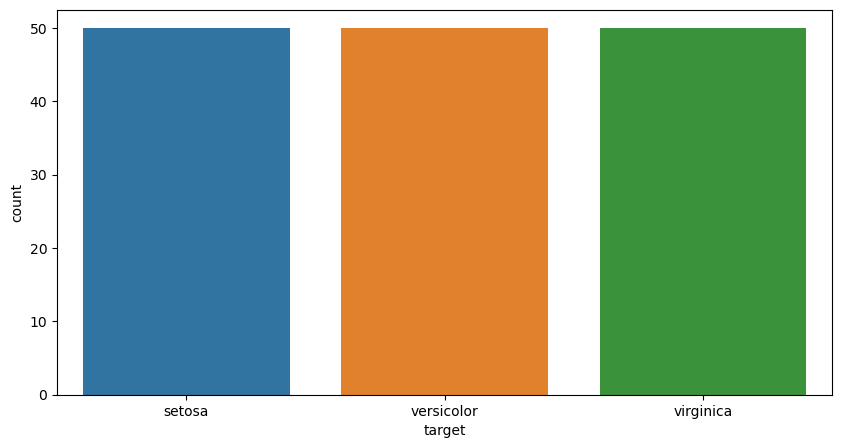

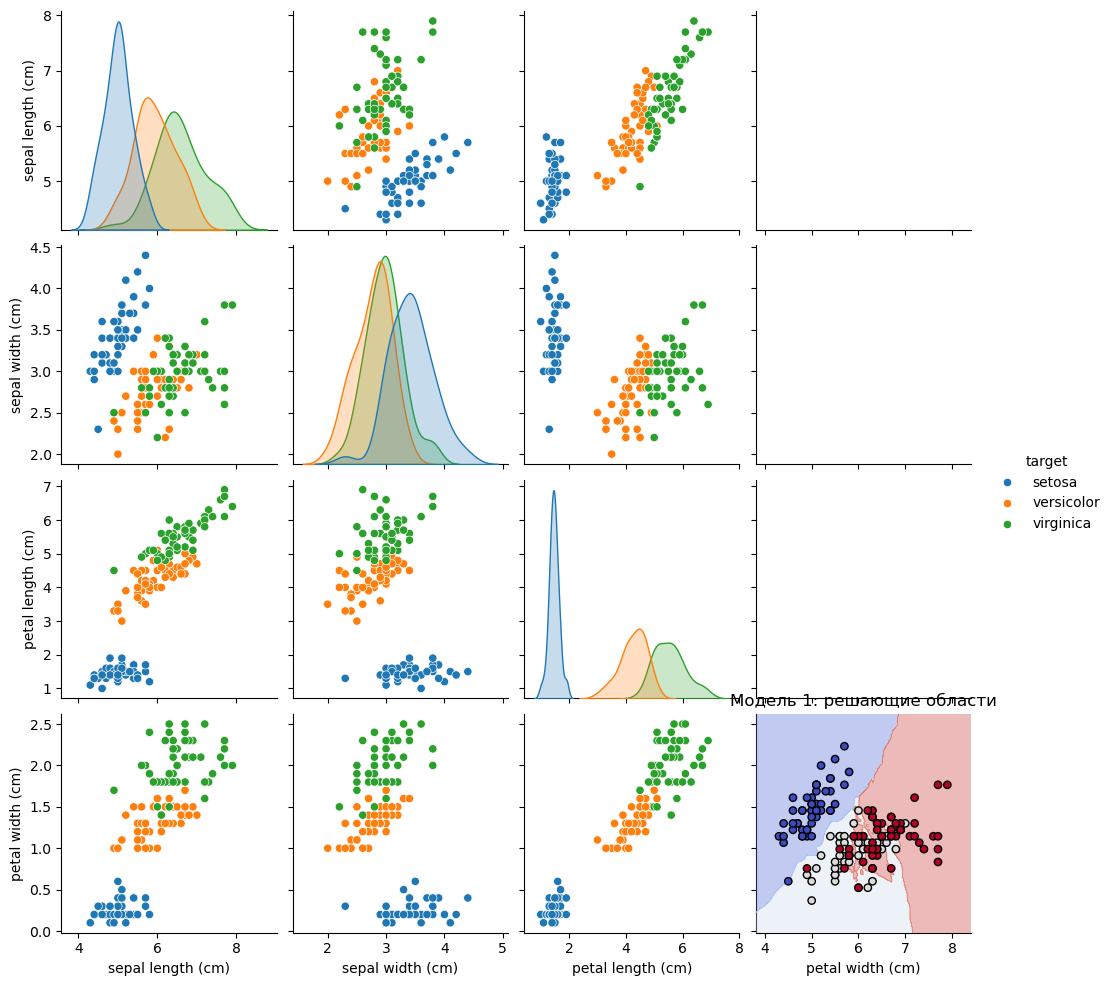

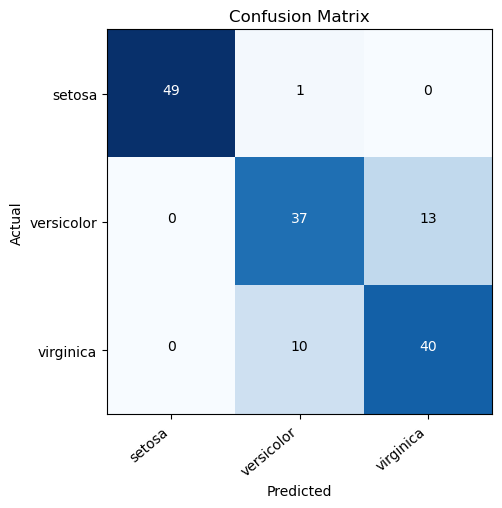

In [14]:
# Матрица ошибок модели 1 на тех же данных, на которых она училась.
y_hat = model_1.predict(X)
labels = df["target"].unique()

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 2 (длина и ширина лепестка)</h1>  
Теперь для нашей второй модели мы собираемся использовать функции длины и ширины лепестка в качестве входных данных.

In [15]:
# Модель 2: длина и ширина лепестка.
X = df[['petal length (cm)', 'petal width (cm)']]

model_2 = KNeighborsClassifier()
model_2.fit(X, y_true)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


__Model 2 Evaluation__

In [16]:
# Та же диаграмма для длины и ширины лепестка.
plot_decision_regions(X.values, y_true.values.astype(int), model_2)
plt.xlabel('длина лепестка, см')
plt.ylabel('ширина лепестка, см')
plt.title('Модель 2: решающие области')


Text(0.5, 1.0, 'Модель 2: решающие области')

[[50  0  0]
 [ 0 47  3]
 [ 0  3 47]]


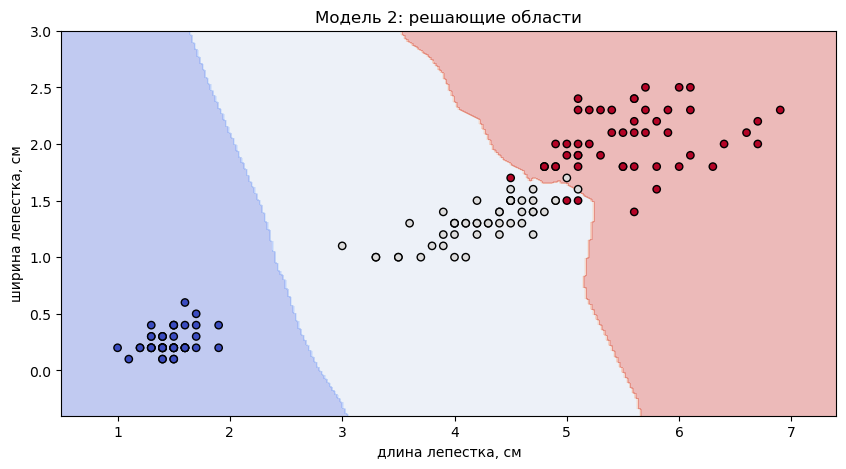

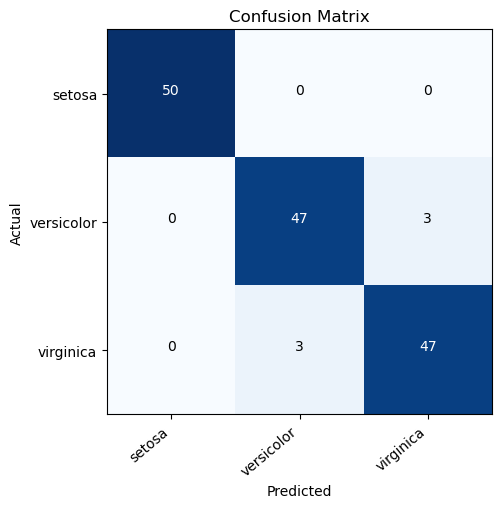

In [17]:
# Матрица ошибок модели 2, тоже на всей выборке.
y_hat = model_2.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

<h1>Модель 3 (все функции)</h1>  
Теперь что касается нашей окончательной модели, мы собираемся использовать все доступные функции и обучить нашу модель KNN.

In [18]:
# Модель 3 получает все четыре измерения. Столбец target в признаки не входит.
X = df.drop(['target'], axis=1)

In [19]:
# kNN с параметрами по умолчанию: 5 соседей, евклидово расстояние.
model_3 = KNeighborsClassifier()
model_3.fit(X, y_true)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


__Модель 3 Оценка__

[[50  0  0]
 [ 0 47  3]
 [ 0  2 48]]


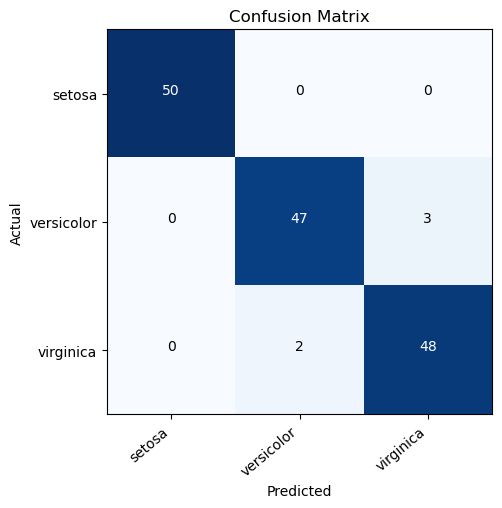

In [20]:
# Матрица ошибок модели по всем признакам.
y_hat = model_3.predict(X)

matrix = confusion_matrix(y_true, y_hat, labels=labels, normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Вы можете видеть, что окончательная модель со всеми функциями работает лучше, чем все другие модели. Меньше ошибочной классификации.

Однако до сих пор мы обучали и оценивали наши модели в одном и том же наборе данных. Использование одних и тех же данных для обучения и оценки не рекомендуется.

__Модель на разделенном наборе данных__

Здесь мы разделим наш набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. Позже во время оценки мы собираемся использовать наш изолированный набор тестов.

In [21]:
# 30% объектов уходим в тест. stratify сохраняет доли трёх видов.
X = df.drop(['target'], axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3)

In [22]:
# Эту модель учим только на обучающей части.
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [23]:
# Прогноз на тесте. В отчёт передаём сначала истинные метки, затем прогноз:
# именно в таком порядке classification_report считает precision, recall и F1.
preds = knn.predict(X_test)
print(classification_report(y_test, preds))


              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00        15
         1.0       1.00      0.87      0.93        15
         2.0       0.88      1.00      0.94        15

    accuracy                           0.96        45
   macro avg       0.96      0.96      0.96        45
weighted avg       0.96      0.96      0.96        45



[[15  0  0]
 [ 0 13  2]
 [ 0  0 15]]


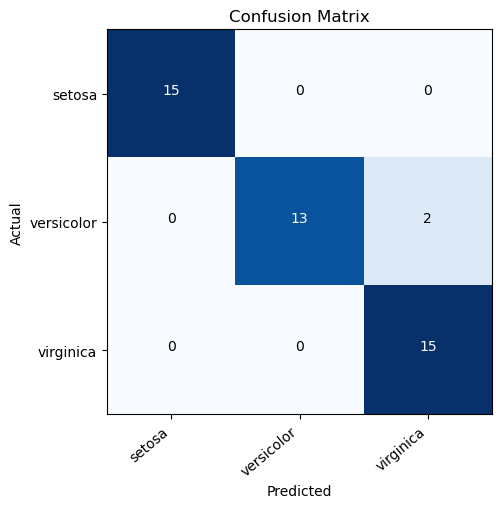

In [24]:
# Матрица ошибок уже на отложенных объектах, которых модель не видела.
matrix = confusion_matrix(y_test, preds, labels=y.unique(), normalize=None)
print(matrix)

display_confusion_matrix(matrix, dataset.target_names)

Выше вы можете видеть, что точность нашего набора тестовых данных составляет 98%.

Из матрицы путаницы мы также видим, что у нас очень низкий уровень ошибок классификации.

Для наших вышеупомянутых моделей мы также можем использовать данные обучения и тестирования отдельно, оценивать эти модели, а затем выбирать лучшую модель.

<h1>Задание</h1>  
С помощью метода kNN определить качество красного вина. Использовать датасет winequality-red.csv, который находится в папке data.
Для этого разделить набор данных на обучающий и тестовый набор и обучим нашу модель в обучающем наборе. 
Построить матрицу путаници. Сделать выводы по полученным результатам. 

---

# Индивидуальное задание. Качество красного вина, метод k ближайших соседей

Нужно по химическому составу предсказать оценку `quality` из файла `winequality-red.csv`.
В условии файл указан в папке `data`, в этой работе он лежит рядом с тетрадью.

Дальше делаем то же, что и для ирисов на отложенной выборке:

1. смотрим состав данных и баланс классов;
2. отделяем тест и не используем его при выборе параметров;
3. обучаем kNN только на обучающей части;
4. строим матрицу ошибок;
5. считаем accuracy, precision, recall и F1.

Оценка вина — это несколько классов, и они разного размера. Поэтому precision, recall и F1 приводим двумя способами усреднения: **weighted** (класс берётся с весом своей доли, эти четыре числа и сдаём) и **macro** (каждый балл равноправен, редкие оценки 3 и 8 тянут среднее вниз).


In [25]:
# Повторный импорт, чтобы индивидуальную часть можно было запустить отдельно от теории.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 4.5)
# В DejaVu Sans есть кириллица, подписи графиков остаются читаемыми.
plt.rcParams['font.family'] = 'DejaVu Sans'
pd.set_option('display.float_format', lambda value: f'{value:0.4f}')


In [26]:
from pathlib import Path

# Ищем файл и рядом с тетрадью, и в папке data — как сказано в условии.
data_candidates = [Path('winequality-red.csv'), Path('data') / 'winequality-red.csv']
data_path = next((path for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Не найден winequality-red.csv рядом с тетрадью или в папке data.')

wine = pd.read_csv(data_path)
print('Файл:', data_path)
print('Размер таблицы:', wine.shape)

# Последний столбец — балл качества, его и предсказываем. Остальные столбцы — признаки.
print('Столбцы:', list(wine.columns))
display(wine.head())
wine.info()
print('Пропусков в таблице:', int(wine.isna().sum().sum()))
print('Сколько образцов на каждый балл:')
display(wine['quality'].value_counts().sort_index().rename('число образцов').to_frame())


Файл: winequality-red.csv
Размер таблицы: (1599, 12)
Столбцы: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
Пропусков в таблице: 0
Сколько образцов на каждый балл:


,число образцов
quality,
3,10
4,53
5,681
6,638
7,199
8,18


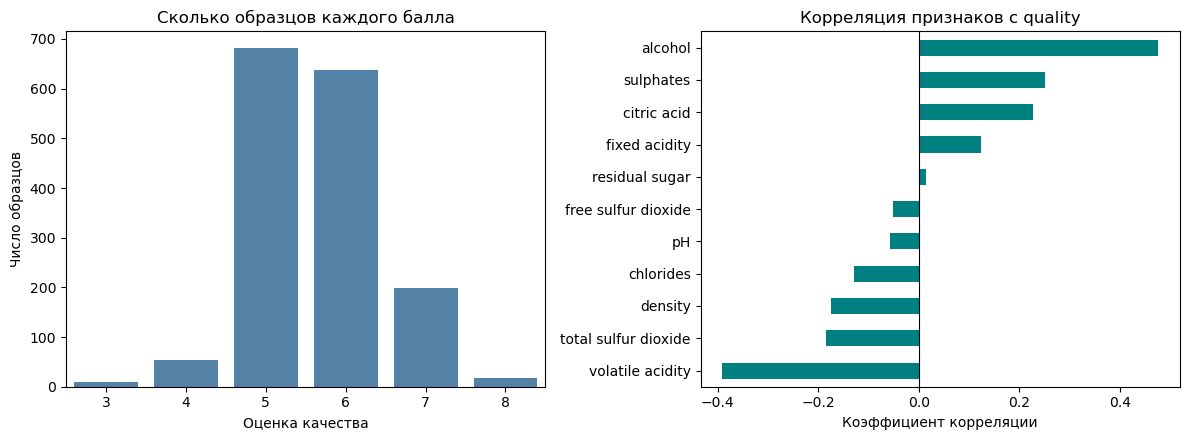

Корреляция с quality по убыванию модуля:


,корреляция с quality
alcohol,0.4762
volatile acidity,-0.3906
sulphates,0.2514
citric acid,0.2264
total sulfur dioxide,-0.1851
density,-0.1749
chlorides,-0.1289
fixed acidity,0.1241
pH,-0.0577
free sulfur dioxide,-0.0507


In [27]:
# Баллы 5 и 6 составляют почти всю выборку, баллы 3 и 8 — редкие.
# kNN на редкий класс смотрит плохо: у такого объекта мало похожих соседей своего класса.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(x='quality', data=wine, color='steelblue', ax=axes[0])
axes[0].set_title('Сколько образцов каждого балла')
axes[0].set_xlabel('Оценка качества')
axes[0].set_ylabel('Число образцов')

# Линейная связь с баллом. Знак показывает направление, модуль — силу.
# Это ещё не модель, только подсказка, какие столбцы вообще связаны с quality.
corr_with_quality = wine.corr(numeric_only=True)['quality'].drop('quality').sort_values()
corr_with_quality.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title('Корреляция признаков с quality')
axes[1].set_xlabel('Коэффициент корреляции')
axes[1].axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

print('Корреляция с quality по убыванию модуля:')
order = corr_with_quality.abs().sort_values(ascending=False).index
display(corr_with_quality.reindex(order).rename('корреляция с quality').to_frame())


## Обучающая и тестовая выборки

Тест — 30% объектов, как в примере с ирисами. `stratify` сохраняет доли баллов и в обучении, и в тесте: иначе редкий балл 3 может целиком уехать в одну из частей. `random_state` фиксирует разбиение, чтобы цифры при повторном запуске не менялись.


In [28]:
X = wine.drop(columns='quality')
y = wine['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y,
)

print('Обучение:', X_train.shape[0], 'объектов,', X_train.shape[1], 'признаков')
print('Тест:', X_test.shape[0], 'объектов')
print('Доли баллов в тесте:')
display(y_test.value_counts(normalize=True).sort_index().rename('доля').to_frame())


Обучение: 1119 объектов, 11 признаков
Тест: 480 объектов
Доли баллов в тесте:


,доля
quality,
3,0.0063
4,0.0333
5,0.4250
6,0.4000
7,0.1250
8,0.0104


## Модель kNN

Соседей ищем по расстоянию, поэтому масштаб столбцов важен. Свободный диоксид серы измерен десятками, плотность — долями единицы. Без выравнивания масштаба соседство определяет столбец с большими числами.

`StandardScaler` стоит внутри `Pipeline`. На кросс-валидации он заново учится на каждом обучающем фолде и не видит фолд, по которому считаем ошибку.

Число соседей `k`, способ взвешивания и расстояние выбираем по взвешенному F1 на 5 фолдах. Взвешенный F1, а не accuracy: accuracy почти не замечает, что редкие баллы не угадываются. Тест в этом переборе не участвует.


In [29]:
pipeline = Pipeline([
    # Сначала приводим признаки к нулевому среднему и единичной дисперсии.
    ('scaler', StandardScaler()),
    # k, веса и метрика подставятся из сетки. Здесь записаны значения по умолчанию.
    ('knn', KNeighborsClassifier()),
])

param_grid = {
    # Нечётное и чётное k оба допустимы: при чётном k голосование может закончиться ничьей,
    # scikit-learn тогда выбирает класс с меньшим номером среди победителей.
    'knn__n_neighbors': list(range(1, 31)),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan'],
}

# Пять фолдов со стратификацией: в каждом фолде сохраняются доли баллов.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='f1_weighted',
    n_jobs=-1,
    refit=True,  # после выбора параметров заново учим модель уже на всём обучении
)
search.fit(X_train, y_train)

print('Лучшие параметры:', search.best_params_)
print(f'Взвешенный F1 на кросс-валидации: {search.best_score_:.4f}')

# Отдельная модель с параметрами по умолчанию (k = 5, евклидово расстояние, равные веса).
# Нужна как точка отсчёта: дал ли подбор k что-то сверх учебника.
default_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier()),
])
default_knn.fit(X_train, y_train)


Лучшие параметры: {'knn__metric': 'manhattan', 'knn__n_neighbors': 21, 'knn__weights': 'distance'}
Взвешенный F1 на кросс-валидации: 0.6482


,steps,"[('scaler', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


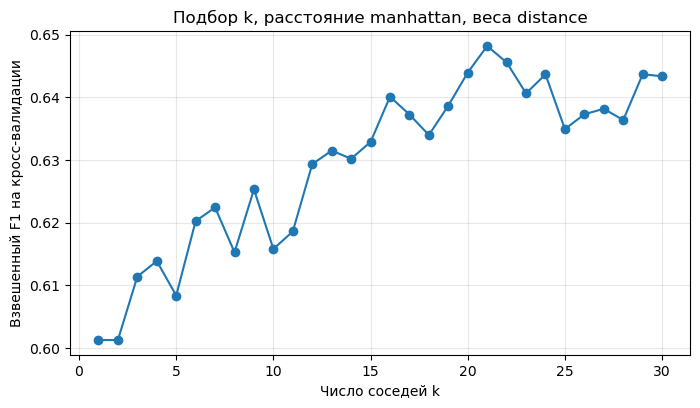

In [30]:
# Кривая качества для победившей пары «метрика + веса». По ней видно, зачем вообще перебирали k.
cv_table = pd.DataFrame(search.cv_results_)
best_metric = search.best_params_['knn__metric']
best_weights = search.best_params_['knn__weights']
mask = (
    (cv_table['param_knn__metric'] == best_metric)
    & (cv_table['param_knn__weights'] == best_weights)
)
curve = cv_table.loc[mask].sort_values('param_knn__n_neighbors')

plt.figure(figsize=(8, 4.2))
plt.plot(
    curve['param_knn__n_neighbors'].astype(int),
    curve['mean_test_score'],
    marker='o',
)
plt.xlabel('Число соседей k')
plt.ylabel('Взвешенный F1 на кросс-валидации')
plt.title(f'Подбор k, расстояние {best_metric}, веса {best_weights}')
plt.grid(True, alpha=0.3)
plt.show()


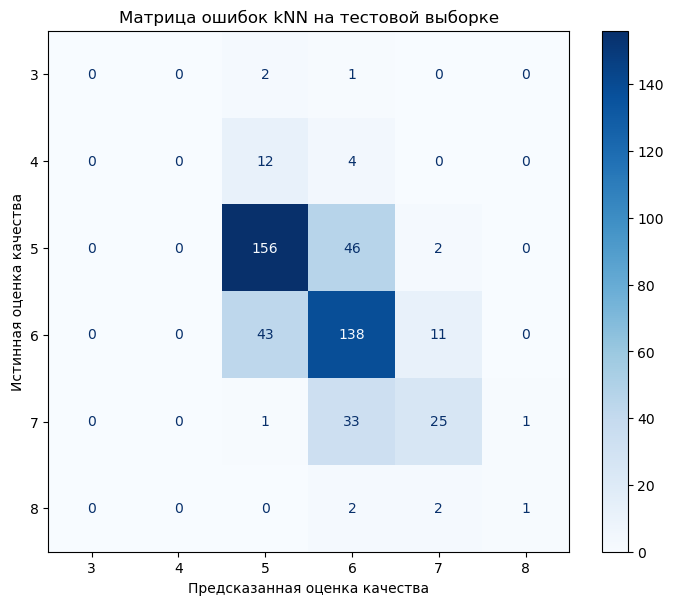

Матрица в числах. Строка — истинный балл, столбец — прогноз.


,прогноз 3,прогноз 4,прогноз 5,прогноз 6,прогноз 7,прогноз 8
истина 3,0,0,2,1,0,0
истина 4,0,0,12,4,0,0
истина 5,0,0,156,46,2,0
истина 6,0,0,43,138,11,0
истина 7,0,0,1,33,25,1
истина 8,0,0,0,2,2,1


In [31]:
# Прогноз только по тесту. Обучающую выборку для итоговых цифр не используем:
# на ней модель видела ответы и оценка была бы завышена.
y_pred = search.predict(X_test)
y_pred_default = default_knn.predict(X_test)
labels = sorted(y.unique())

fig, ax = plt.subplots(figsize=(7.2, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    ax=ax,
    cmap='Blues',
)
ax.set_title('Матрица ошибок kNN на тестовой выборке')
ax.set_xlabel('Предсказанная оценка качества')
ax.set_ylabel('Истинная оценка качества')
plt.tight_layout()
plt.show()

print('Матрица в числах. Строка — истинный балл, столбец — прогноз.')
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=labels),
    index=[f'истина {label}' for label in labels],
    columns=[f'прогноз {label}' for label in labels],
))


In [32]:
def multiclass_row(name, y_true, y_hat):
    """Четыре требуемые характеристики плюс macro-вариант для редких баллов."""
    accuracy = accuracy_score(y_true, y_hat)
    return {
        'модель': name,
        'accuracy': accuracy,
        'precision_weighted': precision_score(y_true, y_hat, average='weighted', zero_division=0),
        'recall_weighted': recall_score(y_true, y_hat, average='weighted', zero_division=0),
        'F1_weighted': f1_score(y_true, y_hat, average='weighted', zero_division=0),
        'precision_macro': precision_score(y_true, y_hat, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_hat, average='macro', zero_division=0),
        'F1_macro': f1_score(y_true, y_hat, average='macro', zero_division=0),
    }

# Константа «всегда самый частый балл обучения». Её accuracy — нижняя планка.
majority_label = y_train.mode().iloc[0]
majority_pred = np.full(shape=y_test.shape, fill_value=majority_label)

metrics = pd.DataFrame([
    multiclass_row('константа: самый частый балл', y_test, majority_pred),
    multiclass_row('kNN по умолчанию, k = 5', y_test, y_pred_default),
    multiclass_row('kNN после подбора параметров', y_test, y_pred),
])
print('Сравнение на одной и той же тестовой выборке:')
display(metrics)

# Эти четыре числа сдаём вместе с матрицей ошибок.
final = metrics.loc[metrics['модель'] == 'kNN после подбора параметров'].iloc[0]
print('Основные характеристики классификатора на тесте (взвешенное среднее по классам):')
print(f"accuracy  = {final['accuracy']:.4f}")
print(f"precision = {final['precision_weighted']:.4f}")
print(f"recall    = {final['recall_weighted']:.4f}")
print(f"F1        = {final['F1_weighted']:.4f}")
print()
print('Для одного верного класса на объект micro-precision, micro-recall и micro-F1 равны accuracy.')
print('Macro-средние ниже взвешенных: баллы 3, 4 и 8 модель почти не выделяет, а macro считает их наравне с баллами 5 и 6.')
print()
print('Отчёт по каждому баллу. support — сколько таких бутылок в тесте.')
print(classification_report(y_test, y_pred, zero_division=0, digits=4))


Сравнение на одной и той же тестовой выборке:


,модель,accuracy,precision_weighted,recall_weighted,F1_weighted,precision_macro,recall_macro,F1_macro
0,константа: самый частый балл,0.4250,0.1806,0.4250,0.2535,0.0708,0.1667,0.0994
1,"kNN по умолчанию, k = 5",0.5854,0.5537,0.5854,0.5676,0.2813,0.2805,0.2792
2,kNN после подбора параметров,0.6667,0.6396,0.6667,0.6481,0.4117,0.3500,0.3659


Основные характеристики классификатора на тесте (взвешенное среднее по классам):
accuracy  = 0.6667
precision = 0.6396
recall    = 0.6667
F1        = 0.6481

Для одного верного класса на объект micro-precision, micro-recall и micro-F1 равны accuracy.
Macro-средние ниже взвешенных: баллы 3, 4 и 8 модель почти не выделяет, а macro считает их наравне с баллами 5 и 6.

Отчёт по каждому баллу. support — сколько таких бутылок в тесте.
              precision    recall  f1-score   support

           3     0.0000    0.0000    0.0000         3
           4     0.0000    0.0000    0.0000        16
           5     0.7290    0.7647    0.7464       204
           6     0.6161    0.7188    0.6635       192
           7     0.6250    0.4167    0.5000        60
           8     0.5000    0.2000    0.2857         5

    accuracy                         0.6667       480
   macro avg     0.4117    0.3500    0.3659       480
weighted avg     0.6396    0.6667    0.6481       480



## Выводы

Оценки качества распределены очень неравномерно: баллов 5 и 6 сотни, баллов 3 и 8 — единицы. Из-за этого голой accuracy недостаточно. Для сдачи берём четыре числа с тестовой выборки у подобранного kNN. Усреднение взвешенное: класс входит в среднее пропорционально числу бутылок.

Основные характеристики классификатора на тесте:

- accuracy = 0.6667
- precision = 0.6396
- recall = 0.6667
- F1 = 0.6481

Параметры этой модели: 21 сосед, манхэттенское расстояние, вес соседа обратно пропорционален расстоянию. Macro-F1 на том же тесте равен 0.3659. Он ниже, потому что баллы 3, 4 и 8 модель почти не называет, а macro-среднее ставит их в один ряд с баллами 5 и 6.

Матрица ошибок собрана вдоль соседних баллов. Чаще всего путаются 5 и 6, затем 6 и 7. Для дегустационной шкалы это естественная ошибка: состав вина у соседних оценок перекрывается, резкой границы нет.

Сильнее всего с баллом связаны содержание алкоголя (корреляция +0.48) и летучая кислотность (корреляция −0.39). Остальные признаки слабее. kNN учитывает их все сразу, уже после стандартизации.

Параметры выбирали только по обучению. Тест оставлен для одной итоговой проверки. Подобранная модель выше и константы «всегда самый частый балл» (accuracy 0.4250), и kNN с k = 5 из учебного примера (accuracy 0.5854). Стандартизация здесь обязательна: без неё расстояние определяет не химия вина, а столбец с самым крупным размахом чисел.

Практический предел метода на этих данных виден по редким баллам. Пока образцов с оценкой 3, 4 или 8 так мало, ближайшие соседи почти всегда приходят из классов 5 и 6, и редкую оценку классификатор не восстанавливает.
